In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
train_df = pd.read_csv("UNSW_NB15_training-set.csv")

print("Dataset shape:", train_df.shape)

Dataset shape: (175341, 45)


In [3]:
unselected_col = ["id", "attack_cat", "label"]

x = train_df.drop(columns=unselected_col)
y = train_df["label"]

In [4]:
categorical_cols = x.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = x.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical features:", categorical_cols)
print("Number of categorical features:", len(categorical_cols))

print("\nNumber of numerical features:", len(numerical_cols))

Categorical features: ['proto', 'service', 'state']
Number of categorical features: 3

Number of numerical features: 39


C:\Users\mssai\AppData\Local\Temp\ipykernel_3372\3797923286.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = x.select_dtypes(


In [5]:
print("X shape:", x.shape)
print("y shape:", y.shape)
print("Missing values in X:", x.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

X shape: (175341, 42)
y shape: (175341,)
Missing values in X: 0
Missing values in y: 0


In [6]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

In [7]:
#For Numerial Data
numerical_pipline=Pipeline([("imputer", SimpleImputer(strategy="median")),
                             ("scaler", StandardScaler())])

In [8]:
#Categorical Data
categorical_pipeline=Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                 ("onehot", OneHotEncoder(handle_unknown="ignore"))])

In [9]:
prepocessor=ColumnTransformer([("num", numerical_pipline, numerical_cols),
                               ("cat", categorical_pipeline, categorical_cols)])

In [10]:
model_pipeline = Pipeline([
    ("preprocessing",prepocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [11]:
from sklearn.model_selection import  StratifiedKFold, cross_validate,cross_val_score
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [12]:
scoring = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc"
]

In [13]:
scores=cross_validate(model_pipeline,x,y,cv=cv,scoring=scoring,n_jobs=-1, return_train_score=True)

In [14]:
scores

{'fit_time': array([19.27188754, 26.16891336, 22.79861593, 18.152776  , 18.86518598]),
 'score_time': array([1.32975483, 0.74369454, 0.91789961, 1.18073916, 1.38813901]),
 'test_accuracy': array([0.93338846, 0.93441314, 0.9355823 , 0.93675145, 0.93569636]),
 'train_accuracy': array([0.93605281, 0.9355685 , 0.93526195, 0.93493402, 0.93504096]),
 'test_precision': array([0.91963207, 0.92207436, 0.92216622, 0.92407741, 0.92426681]),
 'train_precision': array([0.92332387, 0.92309952, 0.92237215, 0.92197396, 0.92249738]),
 'test_recall': array([0.98852068, 0.9870538 , 0.98881347, 0.98826881, 0.98634155]),
 'train_recall': array([0.98810122, 0.98760906, 0.9880385 , 0.98801755, 0.98752527]),
 'test_f1': array([0.95283286, 0.95345825, 0.95432765, 0.95509576, 0.95429579]),
 'train_f1': array([0.95461491, 0.9542653 , 0.95407676, 0.95385393, 0.95390437]),
 'test_roc_auc': array([0.98326753, 0.98418364, 0.98493083, 0.98474501, 0.98396572]),
 'train_roc_auc': array([0.98444041, 0.9843919 , 0.984158

In [15]:
from sklearn.model_selection import cross_val_predict
y_pred=cross_val_predict(model_pipeline,x,y,cv=cv,n_jobs=-1)

In [16]:
from sklearn.metrics import confusion_matrix

In [17]:
cm=confusion_matrix(y,y_pred)

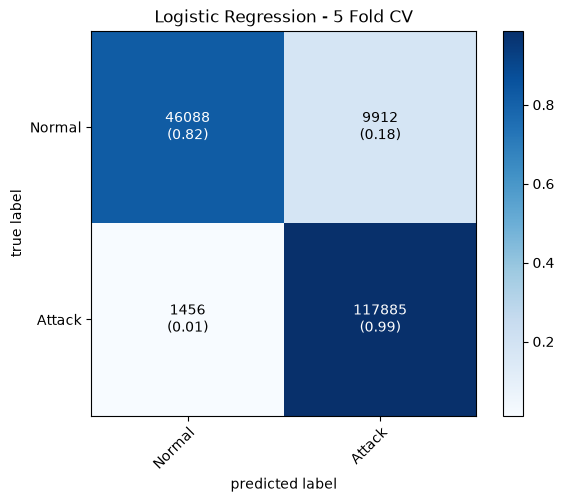

In [18]:
from mlxtend.plotting import plot_confusion_matrix
fig, ax = plot_confusion_matrix(
    conf_mat=cm,
    class_names=["Normal", "Attack"],
    show_absolute=True,
    show_normed=True,
    colorbar=True,
    figsize=(7, 5)
)

plt.title("Logistic Regression - 5 Fold CV")
plt.show()

In [35]:
y_prob= cross_val_predict(model_pipeline,x,y,cv=cv,n_jobs=-1,method="predict_proba")[:,:-1]

In [38]:
y_prob = 1 - y_prob.ravel()

In [39]:
from sklearn.metrics import roc_curve, roc_auc_score
fpr, tpr, thresholds = roc_curve(y, y_prob)
roc_auc = roc_auc_score(y, y_prob)
print("ROC-AUC Score:", round(roc_auc, 4))


ROC-AUC Score: 0.9842


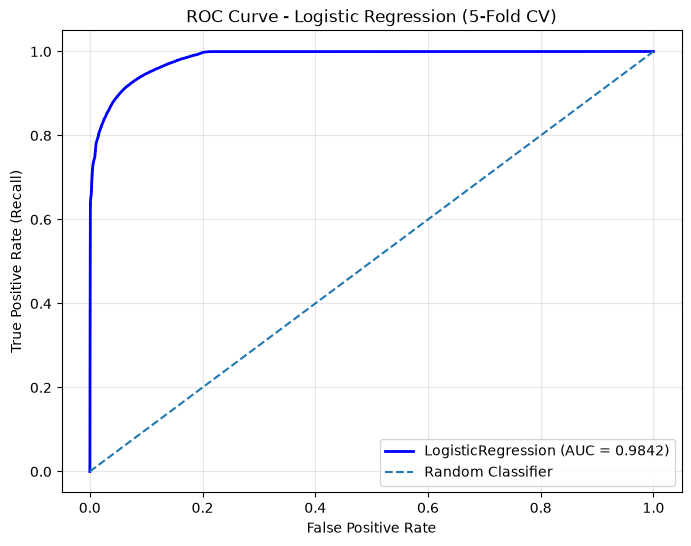

In [40]:
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', label=f"LogisticRegression (AUC = {roc_auc:.4f})",linewidth=2)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve - Logistic Regression (5-Fold CV)")

plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [41]:
print("y shape:", y.shape)
print("y_prob shape:", y_prob.shape)

y shape: (175341,)
y_prob shape: (175341,)


In [43]:
print(pd.DataFrame({
    "Actual_Label": y,
    "Attack_Probability": y_prob
}).groupby("Actual_Label")["Attack_Probability"].mean())

Actual_Label
0    0.138289
1    0.935136
Name: Attack_Probability, dtype: float64


In [44]:
roc_auc = roc_auc_score(y, y_prob)
print("ROC-AUC:", round(roc_auc, 4))

ROC-AUC: 0.9842


In [45]:
from sklearn.metrics import precision_recall_curve, average_precision_score

In [46]:
precision,recall, thresholds = precision_recall_curve(y, y_prob)
average_precision = average_precision_score(y, y_prob)
print("Average Precision:", round(average_precision, 4))

Average Precision: 0.9917


[]

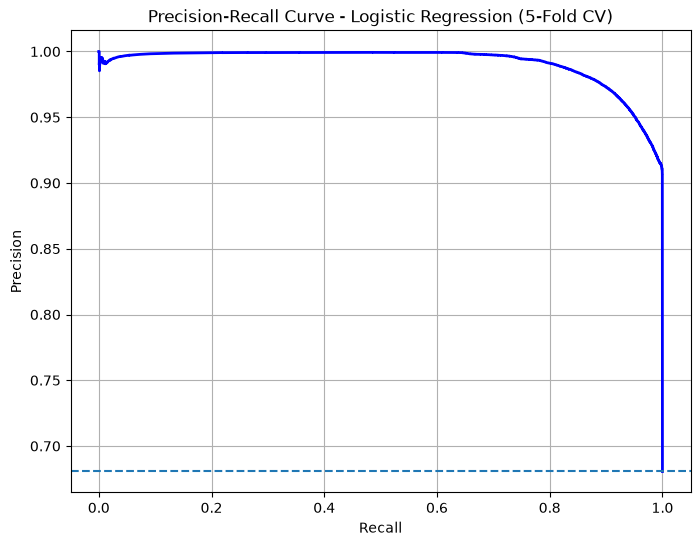

In [48]:
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, color='blue', label=f"LogisticRegression (AP = {average_precision:.4f})",
         linewidth=2)
plt.axhline(
    y=y.mean(),
    linestyle="--",
    label=f"Random baseline = {y.mean():.2f}"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Logistic Regression (5-Fold CV)")
plt.grid()
plt.plot()

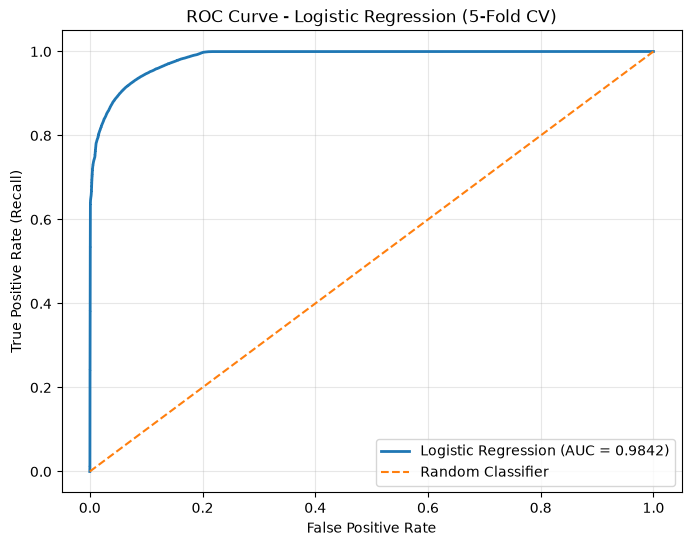

In [49]:
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.4f})",
    linewidth=2
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve - Logistic Regression (5-Fold CV)")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [50]:
from sklearn.metrics import precision_score,recall_score,f1_score

In [54]:
thresholds=np.arange(0.1,1.0,0.05)
results = []

In [55]:
for i in thresholds:
    y_pred_threshold = (y_prob >= i).astype(int)
    precision = precision_score(y, y_pred_threshold)
    recall = recall_score(y, y_pred_threshold)
    f1 = f1_score(y, y_pred_threshold)
    results.append({ "threshold": i, "precision": precision, "recall": recall, "f1": f1 })

In [56]:
threshold_results_df = pd.DataFrame(results)

In [57]:
threshold_results_df 

,threshold,precision,recall,f1
0,0.10,0.911983,0.998802,0.953420
1,0.15,0.913300,0.998224,0.953875
2,0.20,0.914247,0.997252,0.953947
3,0.25,0.915000,0.996179,0.953865
4,0.30,0.915786,0.994956,0.953731
5,0.35,0.916622,0.993774,0.953640
6,0.40,0.917765,0.992392,0.953621
7,0.45,0.919857,0.990799,0.954011
8,0.50,0.922439,0.987800,0.954001
9,0.55,0.926978,0.983300,0.954309


In [58]:
best_row = threshold_results_df.loc[
    threshold_results_df["f1"].idxmax()]
print(best_row)

threshold    0.550000
precision    0.926978
recall       0.983300
f1           0.954309
Name: 9, dtype: float64


In [62]:
y_pred_055= (y_prob >= 0.55).astype(int)
cm1=confusion_matrix(y,y_pred_055)
tn, fp, fn, tp = cm.ravel()

fpr = fp / (fp + tn)
fnr = fn / (fn + tp)

print("FPR:", round(fpr, 4))
print("FNR:", round(fnr, 4))

FPR: 0.177
FNR: 0.0122


In [63]:
print("Actual y distribution:")
print(y.value_counts())

print("\ny_pred_055 distribution:")
print(pd.Series(y_pred_055).value_counts())

print("\nShapes:")
print("y:", y.shape)
print("y_prob:", y_prob.shape)
print("y_pred_055:", y_pred_055.shape)

print("\nConfusion Matrix:")
print(confusion_matrix(y, y_pred_055, labels=[0, 1]))

Actual y distribution:
label
1    119341
0     56000
Name: count, dtype: int64

y_pred_055 distribution:
1    126592
0     48749
Name: count, dtype: int64

Shapes:
y: (175341,)
y_prob: (175341,)
y_pred_055: (175341,)

Confusion Matrix:
[[ 46756   9244]
 [  1993 117348]]


In [61]:
from sklearn.metrics import classification_report

print(classification_report(
    y,
    y_pred_055,
    target_names=["Normal", "Attack"]
))

              precision    recall  f1-score   support

      Normal       0.96      0.83      0.89     56000
      Attack       0.93      0.98      0.95    119341

    accuracy                           0.94    175341
   macro avg       0.94      0.91      0.92    175341
weighted avg       0.94      0.94      0.93    175341



In [73]:
threshold_results_clean = []

for threshold in np.arange(0.50, 0.61, 0.01):

    y_pred_temp = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y, y_pred_temp, labels=[0, 1]
    ).ravel()

    threshold_results_clean.append({
        "Threshold": threshold,
        "Precision": precision_score(y, y_pred_temp, zero_division=0),
        "Recall": recall_score(y, y_pred_temp, zero_division=0),
        "F1-Score": f1_score(y, y_pred_temp, zero_division=0),
        "FPR": fp / (fp + tn),
        "FNR": fn / (fn + tp)
    })

# Create a completely new DataFrame
threshold_df_clean = pd.DataFrame(threshold_results_clean)

print("Shape:", threshold_df_clean.shape)
print("Missing values:\n", threshold_df_clean.isnull().sum())

threshold_df_clean.round(4)

Shape: (11, 6)
Missing values:
 Threshold    0
Precision    0
Recall       0
F1-Score     0
FPR          0
FNR          0
dtype: int64


,Threshold,Precision,Recall,F1-Score,FPR,FNR
0,0.50,0.9224,0.9878,0.9540,0.1770,0.0122
1,0.51,0.9232,0.9870,0.9541,0.1749,0.0130
2,0.52,0.9240,0.9862,0.9541,0.1728,0.0138
3,0.53,0.9248,0.9853,0.9541,0.1707,0.0147
4,0.54,0.9258,0.9842,0.9541,0.1681,0.0158
5,0.55,0.9270,0.9833,0.9543,0.1651,0.0167
6,0.56,0.9281,0.9822,0.9544,0.1621,0.0178
7,0.57,0.9292,0.9807,0.9543,0.1592,0.0193
8,0.58,0.9305,0.9790,0.9542,0.1558,0.0210
9,0.59,0.9317,0.9773,0.9540,0.1526,0.0227


In [74]:
eligible = threshold_df_clean[
    threshold_df_clean["Recall"] >= 0.98
]

best_row = eligible.loc[eligible["FPR"].idxmin()]

print("Selected threshold:")
print(best_row)

Selected threshold:
Threshold    0.570000
Precision    0.929199
Recall       0.980719
F1-Score     0.954264
FPR          0.159250
FNR          0.019281
Name: 7, dtype: float64


In [75]:
best_threshold = 0.57

print("Selected Threshold:", best_threshold)

Selected Threshold: 0.57
